# Agrupamiento de ventanas horarias — Departamento 1
Cada capa ponderada y no dirigida representa una hora de un día específico del registro: día = timestamp // 86400 y hora = (timestamp // 3600) % 24. Los días no se reducen módulo 7 y no se mezclan semanas. Las ventanas son intervalos [inicio, fin) de 3600 segundos desde el origen temporal; solo se crean las que contienen interacciones entre usuarios distintos. Los huecos temporales se conservan en absolute_hour, start_seconds y end_seconds. El origen no identifica un día del calendario ni una hora local.

La construcción agrupa los eventos una sola vez, sin recorrer todo el registro por cada ventana. El clustering exhaustivo y las matrices densas pueden requerir recursos considerables con este número de capas; los cronómetros y repeticiones solo se ejecutan al ejecutar sus celdas.

Todas las capas contienen el mismo conjunto de usuarios observados en la red completa, todos pertenecientes al Departamento 1. Los IDs se remapean globalmente a índices consecutivos y se conserva su ID original.

Se comparan un baseline aglomerativo exhaustivo y una aproximación por buckets sobre proyecciones de laplacianos normalizados. Cada proyección conserva su desplazamiento aleatorio. No se presupone una garantía de localidad respecto a la distancia Jensen–Shannon cuántica.

El corte se selecciona mediante el codo de q(C), no mediante una prueba de optimalidad. q(C) usa igual peso por cluster y un denominador recalculado en cada paso; su valor final cero es impuesto por la definición. ARI y NMI miden concordancia con el baseline, no exactitud frente a etiquetas verdaderas.
Memoria: se acumula una única suma de matrices de densidad y se conserva un candidato por cluster activo. El baseline sigue seleccionando el mínimo global exacto, recalculando distancias cuando desaparece un vecino; puede tardar más. No se guardan matrices densas por capa ni grafos históricos de fusiones. Los diccionarios devueltos contienen solo clusters activos; Z permite reconstruir membresías. Las copias de entrada comparten topología y solo se reinician cachés.

Por defecto se estudia un intervalo continuo desde el día relativo 0 hasta completar 1,000 capas horarias con interacciones. START_DAY/START_HOUR controlan el inicio; END_DAY/END_HOUR permiten un fin exclusivo opcional y MAX_LAYERS limita las horas activas. No se muestrean horas dispersas. El conjunto de usuarios sigue siendo el del archivo Dept1. Esta selección describe el intervalo elegido, no necesariamente todo el registro.

Esta copia analiza únicamente comunicación interna de Dept1. Sus IDs son locales a esta subred. La composición departamental es constante y no sirve para validar los clusters; el análisis relevante es temporal y de actividad. Los experimentos de clustering no se ejecutaron al preparar la copia.


In [1]:
import numpy as np
import networkx as nx
from scipy.linalg import eig
from heapq import heappush, heappop
from collections import defaultdict
from tqdm import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
import os
import copy
from pathlib import Path
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# ----------------------------------------------------
# 1. Definición del Kernel de Frobenius para LSH
# ----------------------------------------------------

def projection_frobenius(A, B):
    return float(np.sum(A * B))

def hash_p_stable(projection, r, offset):
    if r <= 0:
        return 0
    return int(np.floor((projection + offset) / r))

def get_erdos_renyi_graph(n, p):
    while True:
        g = nx.erdos_renyi_graph(n, p)
        if g.number_of_edges() > 0:
            return g

def get_active_nodes(g):
    if 'active_nodes' in g.graph:
        return g.graph['active_nodes']
    nodes = sorted(list(set([n for n, d in g.degree() if d > 0])))
    g.graph['active_nodes'] = nodes
    return nodes

def get_adjacency(g, N):
    # Dense working array only; never retain one per input layer.
    A = nx.to_numpy_array(g, nodelist=range(N), weight='weight', dtype=float)
    np.fill_diagonal(A, 0)
    return A

def get_density_matrix(A):
    num_edges = np.sum(A) / 2.0
    if num_edges == 0:
        return np.zeros_like(A)
    degrees = np.sum(A, axis=1)
    L = np.diag(degrees) - A
    return L / (2.0 * num_edges)

def entropy_from_rho(rho):
    eigvals = np.linalg.eigvalsh(rho)
    eigvals[eigvals < 1e-12] = 0.0
    eigvals = eigvals[eigvals > 1e-12]
    return float(-np.sum(eigvals * np.log2(eigvals)))

def von_newmann_entropy(g, N_pad=None):
    if 'vn_entropy' in g.graph:
        return g.graph['vn_entropy']

    act = get_active_nodes(g)
    if len(act) == 0:
        entropy = 0.0
    else:
        A = nx.adjacency_matrix(g, nodelist=act, weight='weight').toarray().astype(float)
        sum_A = np.sum(A)
        L = np.diag(np.sum(A, axis=1)) - A
        rho = L / sum_A
        entropy = entropy_from_rho(rho)
        
    g.graph['vn_entropy'] = entropy
    return entropy

def aggregate(g1, g2, N=None):
    g = nx.Graph()
    for u, v, d in g1.edges(data=True):
        g.add_edge(u, v, weight=d.get('weight', 1.0))
    for u, v, d in g2.edges(data=True):
        if g.has_edge(u, v):
            g[u][v]['weight'] += d.get('weight', 1.0)
        else:
            g.add_edge(u, v, weight=d.get('weight', 1.0))
            
    if N is not None:
        g.add_nodes_from(range(N))
    return g

def js_divergence(g1, g2, N_pad=None):
    act1 = get_active_nodes(g1)
    act2 = get_active_nodes(g2)
    union_nodes = sorted(list(set(act1) | set(act2)))
    
    if len(union_nodes) == 0:
        return 0.0
        
    A1 = nx.adjacency_matrix(g1, nodelist=union_nodes, weight='weight').toarray().astype(float)
    A2 = nx.adjacency_matrix(g2, nodelist=union_nodes, weight='weight').toarray().astype(float)
    
    sum_A1 = np.sum(A1)
    sum_A2 = np.sum(A2)
    
    rho1 = (np.diag(np.sum(A1, axis=1)) - A1) / sum_A1 if sum_A1 > 0 else np.zeros_like(A1)
    rho2 = (np.diag(np.sum(A2, axis=1)) - A2) / sum_A2 if sum_A2 > 0 else np.zeros_like(A2)
    
    rho_mix = (rho1 + rho2) / 2.0
    
    h_mix = entropy_from_rho(rho_mix)
    h_avg = (von_newmann_entropy(g1) + von_newmann_entropy(g2)) / 2.0
    val = max(h_mix - h_avg, 0.0)
    return np.sqrt(val)

def get_bucket_id_for_graph(g, random_graphs, B, projection_ranges, N_pad, proj_func):
    bucket_id = ""
    A = get_density_matrix(get_adjacency(g, N_pad))

    for k, erg in enumerate(random_graphs):
        A_er = get_adjacency(erg, N_pad)
        proj = proj_func(A, A_er)

        min_proj, max_proj, offset = projection_ranges[k]
        r = (max_proj - min_proj) / B

        hash_bin = hash_p_stable(proj, r, offset)
        bucket_id += f"{hash_bin}_"

    return bucket_id

def quality(active, clusters, h_total=None, N_pad=None):
    active = list(active)
    if not active:
        return 0.0
    if h_total is None:
        N_pad = N_pad or max(clusters[i].number_of_nodes() for i in active)
        total = np.zeros((N_pad, N_pad))
        for i in active:
            add_density(total, clusters[i])
        h_total = entropy_from_rho(total / len(active))
    return 0.0 if h_total <= 1e-12 else float(
        1 - sum(von_newmann_entropy(clusters[i]) for i in active) / len(active) / h_total)

def get_rho_sub(g):
    act = get_active_nodes(g)
    if len(act) == 0:
        return np.zeros((1, 1))
    A = nx.adjacency_matrix(g, nodelist=act, weight='weight').toarray().astype(float)
    sum_A = np.sum(A)
    return (np.diag(np.sum(A, axis=1)) - A) / sum_A if sum_A > 0 else np.zeros_like(A)


def has_bucket_candidates(bucket_members, active):
    for members in bucket_members.values():
        alive = [x for x in members if x in active]
        if len(alive) >= 2:
            return True
    return False

# ----------------------------------------------------
# 2. Controladores LSH-HLA y Baseline
# ----------------------------------------------------

def build_lsh_buckets(graphs, num_proj, B, proj_func, p_er=0.8):
    num_graphs = len(graphs)
    N_pad = max(g.number_of_nodes() for g in graphs)

    bucket_ids = [""] * num_graphs
    random_graphs = []
    projection_ranges = []

    for k in range(num_proj):
        erg = get_erdos_renyi_graph(N_pad, p_er)
        random_graphs.append(erg)
        A_er = get_adjacency(erg, N_pad)

        projections = []
        for g in graphs:
            A = get_density_matrix(get_adjacency(g, N_pad))
            proj = proj_func(A, A_er)
            projections.append(proj)

        min_proj = min(projections)
        max_proj = max(projections)
        r = (max_proj - min_proj) / B
        offset = np.random.uniform(0, r) if r > 0 else 0.0
        projection_ranges.append((min_proj, max_proj, offset))
        for i in range(num_graphs):
            hash_bin = hash_p_stable(projections[i], r, offset)
            bucket_ids[i] += f"{hash_bin}_"

    buckets = defaultdict(list)
    for i, bid in enumerate(bucket_ids):
        buckets[bid].append(i)

    return buckets, bucket_ids, random_graphs, projection_ranges

def hierarchical_bucket_heap_dynamic(graphs, buckets, bucket_ids, random_graphs,
                                     projection_ranges, B, proj_func, epsilon=np.inf):
    return memory_bounded_hierarchy(
        graphs, epsilon=epsilon, bucket_ids=bucket_ids,
        rehash=lambda g: get_bucket_id_for_graph(
            g, random_graphs, B, projection_ranges,
            graphs[0].number_of_nodes(), proj_func))

def shclust_heap_dynamic(graphs, num_proj=3, B=10, proj_func=projection_frobenius, epsilon=np.inf):
    buckets, bucket_ids, random_graphs, projection_ranges = build_lsh_buckets(
        graphs,
        num_proj=num_proj,
        B=B,
        proj_func=proj_func
    )

    Z, clusters, active, bucket_members = hierarchical_bucket_heap_dynamic(
        graphs=graphs,
        buckets=buckets,
        bucket_ids=bucket_ids,
        random_graphs=random_graphs,
        projection_ranges=projection_ranges,
        B=B,
        proj_func=proj_func,
        epsilon=epsilon
    )

    return Z, clusters, active, bucket_members, bucket_ids

def hierarchical_clustering_heap(graphs, epsilon=np.inf):
    """Exact global minimum, with one nearest candidate per active cluster."""
    Z, clusters, active, _ = memory_bounded_hierarchy(graphs, epsilon=epsilon)
    return Z, clusters, active

# Helper functions for evaluation
def get_cluster_memberships(Z, num_graphs, target_merges):
    memberships = {i: [i] for i in range(num_graphs)}
    active = set(range(num_graphs))
    
    for step in range(min(target_merges, len(Z))):
        row = Z[step]
        c_i = int(row[0])
        c_j = int(row[1])
        new_id = int(row[4])
        
        memberships[new_id] = memberships.pop(c_i) + memberships.pop(c_j)
        active.remove(c_i)
        active.remove(c_j)
        active.add(new_id)
        
    return {c: memberships[c] for c in active}

def get_cluster_labels(Z, num_graphs, k_star):
    cluster_members = get_cluster_memberships(Z, num_graphs, k_star)
    labels = np.zeros(num_graphs, dtype=int)
    for c_idx, (c_id, members) in enumerate(cluster_members.items()):
        for m in members:
            labels[m] = c_idx
    return labels
def elbow_method(q):
    """
    Método del codo basado en distancia perpendicular a la recta
    entre (1, q(1)) y (m, q(m)).
    """
    q = np.asarray(q, dtype=float)
    m = len(q)

    x1, y1 = 1, q[0]
    x2, y2 = m, q[-1]

    dx = x2 - x1
    dy = y2 - y1

    norm = np.sqrt(dx**2 + dy**2)

    distances = np.zeros(m)
    for i in range(m):
        x0 = i + 1
        y0 = q[i]
        area = abs(dy * (x0 - x1) - dx * (y0 - y1))
        distances[i] = area / norm

    k_star = int(np.argmax(distances) + 1)
    return k_star, distances


def fresh_graphs(graphs):
    """Reset numerical caches without duplicating immutable graph topology."""
    for g in graphs:
        for key in ('adjacency', 'active_nodes', 'vn_entropy'):
            g.graph.pop(key, None)
    return list(graphs)


def add_density(total, g, factor=1.0):
    """Accumulate a normalized Laplacian using edges, without a dense copy."""
    weight_sum = sum(d.get('weight', 1.0) for u, v, d in g.edges(data=True) if u != v)
    if weight_sum <= 0:
        return
    scale = factor / (2.0 * weight_sum)
    for u, v, d in g.edges(data=True):
        if u == v:
            continue
        w = d.get('weight', 1.0) * scale
        total[u, u] += w
        total[v, v] += w
        total[u, v] -= w
        total[v, u] -= w


def memory_bounded_hierarchy(graphs, epsilon=np.inf, bucket_ids=None, rehash=None):
    """O(L) candidate storage; exact search within the currently allowed pairs.

    Distances are recomputed when a cached nearest neighbor disappears. This
    trades runtime for bounded memory and does not approximate the baseline.
    Only active aggregate graphs are retained; Z reconstructs past memberships.
    """
    if not graphs:
        return [], {}, set(), defaultdict(set)
    n = len(graphs)
    N = graphs[0].number_of_nodes()
    clusters = dict(enumerate(graphs))
    active = set(clusters)
    bids = dict(enumerate(bucket_ids)) if bucket_ids is not None else {}
    global_mode = bucket_ids is None
    nearest = {}
    rho_sum = np.zeros((N, N), dtype=float)
    for g in tqdm(graphs, desc="Acumulando matrices de densidad"):
        add_density(rho_sum, g)
    Z = []

    def allowed(i, j):
        return i != j and (global_mode or bids[i] == bids[j])

    def candidate(i, j):
        # Stable tie-breaking independent of set traversal.
        a, b = sorted((i, j))
        return (js_divergence(clusters[a], clusters[b]), a, b)

    def refresh(i):
        best = None
        for j in sorted(active):
            if allowed(i, j):
                value = candidate(i, j)
                if best is None or value < best:
                    best = value
        nearest[i] = best

    for i in tqdm(sorted(active), desc="Buscando vecinos iniciales (memoria lineal)"):
        refresh(i)
    progress = tqdm(total=max(n - 1, 0), desc="Fusiones")
    try:
        while len(active) > 1:
            candidates = [v for v in nearest.values() if v is not None]
            if not candidates:
                if global_mode:
                    break
                global_mode = True
                for i in sorted(active):
                    refresh(i)
                continue
            dist, i, j = min(candidates)
            if dist > epsilon:
                break
            same_bucket = bucket_ids is not None and bids[i] == bids[j]
            merged = aggregate(clusters[i], clusters[j], N)
            add_density(rho_sum, clusters[i], -1.0)
            add_density(rho_sum, clusters[j], -1.0)
            add_density(rho_sum, merged)
            new_id = n + len(Z)
            for old in (i, j):
                active.remove(old)
                del clusters[old]
                del nearest[old]
            clusters[new_id] = merged
            active.add(new_id)
            if bucket_ids is not None:
                bids[new_id] = rehash(merged) if not global_mode else "global"
            h_total = entropy_from_rho(rho_sum / len(active))
            q = quality(active, clusters, h_total=h_total, N_pad=N)
            row = [i, j, dist, q, new_id]
            if bucket_ids is not None:
                row += [bids[new_id], same_bucket, global_mode]
            Z.append(row)
            for other in sorted(active - {new_id}):
                old_best = nearest[other]
                if old_best is not None and (i in old_best[1:] or j in old_best[1:]):
                    refresh(other)
                elif allowed(other, new_id):
                    value = candidate(other, new_id)
                    if old_best is None or value < old_best:
                        nearest[other] = value
            refresh(new_id)
            if bucket_ids is not None:
                del bids[i], bids[j]
            progress.update(1)
    finally:
        progress.close()
    members = defaultdict(set)
    if bucket_ids is not None:
        for i in active:
            members[bids[i]].add(i)
    return Z, clusters, active, members


In [2]:
# ----------------------------------------------------
# Carga de Datos y Segmentación Multiplex (Día-Hora)
# ----------------------------------------------------

# Intervalo relativo al origen del registro; fin exclusivo.
START_DAY = 0
START_HOUR = 0
END_DAY = None  # Opcional: acotar el intervalo antes de limitar capas.
END_HOUR = 0
MAX_LAYERS = 1000  # None permite todas las horas activas del intervalo.

file_path = "data/TemporalEmail/email-Eu-core-temporal-Dept1.txt"

print("Cargando datos desde", file_path, "...")
raw_data = np.loadtxt(file_path, dtype=np.int64)

total_emails = len(raw_data)
original_node_ids = np.unique(raw_data[:, :2])
num_nodes = len(original_node_ids)
node_to_index = {int(node): i for i, node in enumerate(original_node_ids)}

print(f"Total de correos (interacciones): {total_emails}")
print(f"Total de nodos (usuarios únicos): {num_nodes}")

# Una ventana por hora absoluta desde el origen del registro.
# Las horas sin interacciones entre usuarios distintos no generan grafos.
ts = raw_data[:, 2]
if np.any(ts < 0):
    raise ValueError("Se esperan timestamps no negativos")
hour_indices = ts // 3600
valid = raw_data[:, 0] != raw_data[:, 1]
valid_events = raw_data[valid]
valid_hours = hour_indices[valid]
order = np.argsort(valid_hours, kind="stable")
sorted_events = valid_events[order]
active_hours, starts, counts = np.unique(valid_hours[order], return_index=True, return_counts=True)
print(f"Capas horarias activas en todo Dept1: {len(active_hours)}")
if START_DAY < 0 or not 0 <= START_HOUR < 24 or not 0 <= END_HOUR < 24:
    raise ValueError("Usa días no negativos y horas entre 0 y 23")
start_hour = START_DAY * 24 + START_HOUR
end_hour = END_DAY * 24 + END_HOUR if END_DAY is not None else int(hour_indices.max()) + 1
if end_hour <= start_hour:
    raise ValueError("El fin debe ser posterior al inicio")
if MAX_LAYERS is not None and (not isinstance(MAX_LAYERS, int) or MAX_LAYERS <= 0):
    raise ValueError("MAX_LAYERS debe ser un entero positivo o None")
selected = np.flatnonzero((active_hours >= start_hour) & (active_hours < end_hour))
if MAX_LAYERS is not None:
    selected = selected[:MAX_LAYERS]
if not len(selected):
    raise ValueError("El intervalo no contiene interacciones válidas")
active_hours, starts, counts = active_hours[selected], starts[selected], counts[selected]
selected_end_hour = min(end_hour, int(active_hours[-1]) + 1)
combinations = [(int(t // 24), int(t % 24)) for t in active_hours]
print(f"Capas seleccionadas: {len(active_hours)}; interacciones: {int(counts.sum())}")
print(f"Intervalo relativo [inicio, fin): día {start_hour // 24}, {start_hour % 24:02d}:00 "
      f"a día {selected_end_hour // 24}, {selected_end_hour % 24:02d}:00")
print(f"Horas sin interacciones omitidas: {selected_end_hour - start_hour - len(active_hours)}")
if MAX_LAYERS is not None and len(active_hours) < MAX_LAYERS:
    print("El intervalo tiene menos horas activas que MAX_LAYERS; se usan todas las disponibles.")
selection_metadata = {
    "start_hour": int(start_hour), "end_hour_exclusive": int(selected_end_hour),
    "layers": int(len(active_hours)), "events": int(counts.sum()),
    "global_users": int(num_nodes),
}

graphs = []
for absolute_hour, start, count in zip(active_hours, starts, counts):
    d, h = divmod(int(absolute_hour), 24)
    chunk = sorted_events[start:start + count]

    g = nx.Graph()
    # Asegurar que todos tengan el mismo conjunto de nodos
    g.add_nodes_from(range(num_nodes))
    g.graph['absolute_hour'] = int(absolute_hour)
    g.graph['start_seconds'] = int(absolute_hour) * 3600
    g.graph['end_seconds'] = (int(absolute_hour) + 1) * 3600
    g.graph['day'] = d
    g.graph['hour'] = h
    g.graph['event_count'] = int(np.count_nonzero(chunk[:, 0] != chunk[:, 1]))
    
    for u, v, _ in chunk:
        u, v = node_to_index[int(u)], node_to_index[int(v)]
        if u == v:
            continue
        if g.has_edge(u, v):
            g[u][v]['weight'] += 1.0
        else:
            g.add_edge(u, v, weight=1.0)
            
    graphs.append(g)

print(f"Segmentación multiplex completada. Se crearon {len(graphs)} grafos (capas).")
print(f"  Ejemplo: Capa 0 -> Día {graphs[0].graph['day']}, Hora {graphs[0].graph['hour']:02d}:00 | Aristas: {graphs[0].number_of_edges()}")

assert all(set(g) == set(range(num_nodes)) for g in graphs)
assert all(g.number_of_edges() > 0 for g in graphs)
selected_users = np.unique(np.concatenate([sorted_events[start:start + count, :2].ravel() for start, count in zip(starts, counts)]))
print(f"Investigadores con actividad en el intervalo seleccionado: {len(selected_users)}")


Cargando datos desde data/TemporalEmail/email-Eu-core-temporal-Dept1.txt ...
Total de correos (interacciones): 61046
Total de nodos (usuarios únicos): 309
Capas horarias activas en todo Dept1: 6186
Capas seleccionadas: 1000; interacciones: 8539
Intervalo relativo [inicio, fin): día 0, 00:00 a día 98, 14:00
Horas sin interacciones omitidas: 1366
Segmentación multiplex completada. Se crearon 1000 grafos (capas).
  Ejemplo: Capa 0 -> Día 0, Hora 00:00 | Aristas: 1
Investigadores con actividad en el intervalo seleccionado: 255


In [3]:
len(graphs)

1000

### 2.1. Visualización de un Subgrafo de la Red (Nodos 0 a 9)
Para mostrar de forma legible la topología de la red sin saturación, visualizamos un subgrafo inducido de los primeros 10 nodos (0 a 9) en el **Snapshot 0** con el estilo de red solicitado.


/tmp/ipykernel_1487482/1411088031.py:22: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


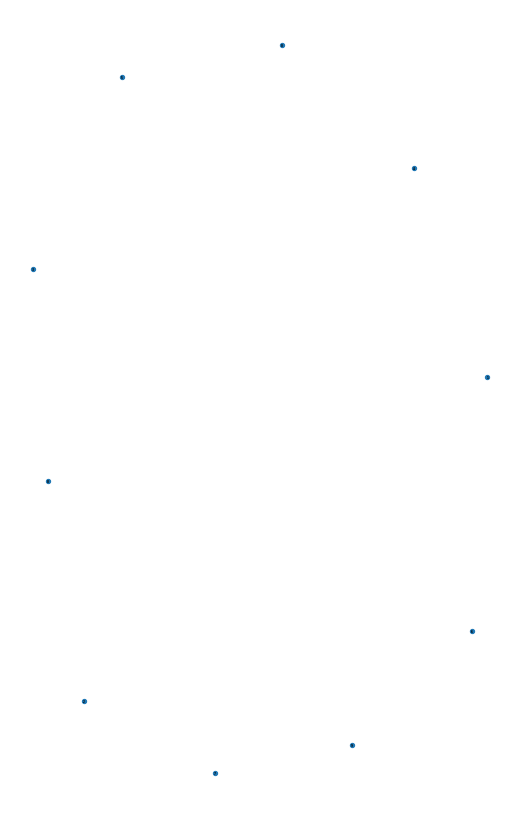

In [4]:
# Obtener el subgrafo inducido de los nodos 0 a 9 en el Snapshot 0
g_sub = graphs[0].subgraph(range(min(10, num_nodes))).copy()

# Calcular distribución espacial
pos = nx.spring_layout(g_sub, seed=42)

# Dibujar con el estilo exacto de la imagen de referencia
plt.figure(figsize=(5, 8), facecolor="white")
nx.draw(
    g_sub,
    pos,
    with_labels=True,
    node_color="#1f77b4",     # Color azul estándar de la imagen
    node_size=8,            # Nodos grandes
    font_weight="bold",       # Texto en negrita
    font_size=2,             # Letra grande
    font_color="black",       # Texto negro dentro de los nodos
    width=0.5,                # Aristas gruesas y negras
    edge_color="black"
)
plt.axis("off")
plt.tight_layout()
plt.show()

### Usuarios del Departamento 1
Todos los usuarios de este archivo pertenecen a Dept1. Se conserva su ID local y no se cruza con IDs de la red completa.


In [5]:
df_investigators_depts = pd.DataFrame({
    "Investigador_ID": original_node_ids,
    "Indice_Matriz": range(num_nodes),
    "Departamento_Principal": "Departamento 1",
})
for g in graphs:
    nx.set_node_attributes(g, {i: int(u) for i, u in enumerate(original_node_ids)}, "original_id")
    nx.set_node_attributes(g, "Departamento 1", "departamento")
df_investigators_depts.to_csv("data/TemporalEmail/investigador_departamento_dept1.csv", index=False)
print(df_investigators_depts["Departamento_Principal"].value_counts())


Departamento_Principal
Departamento 1    309
Name: count, dtype: int64


In [6]:
# ----------------------------------------------------
# 2. Ejecutar Baseline (Sin LSH)
# ----------------------------------------------------
print("=== Ejecutando Clustering Jerárquico Normal (Baseline) ===")
run_graphs = fresh_graphs(graphs)
start_time = time.perf_counter()
Z_baseline, clusters_base, active_base = hierarchical_clustering_heap(run_graphs)
time_baseline = time.perf_counter() - start_time
print(f"Baseline completado en {time_baseline:.2f} segundos.")

# Encontrar codo
df_normal = pd.DataFrame(Z_baseline, columns=["cluster_i", "cluster_j", "dist", "q", "new_cluster_id"])
k_star_normal, _ = elbow_method(df_normal["q"].values)
num_cluster_normal = df_normal.shape[0] - k_star_normal + 1
print(f"Paso de corte seleccionado (k*): {k_star_normal}")
print(f"Número de clusters seleccionado (Baseline): {num_cluster_normal}")

=== Ejecutando Clustering Jerárquico Normal (Baseline) ===


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [43:25<00:00,  2.61s/it]

Baseline completado en 3183.45 segundos.
Paso de corte seleccionado (k*): 983
Número de clusters seleccionado (Baseline): 17


In [7]:
len(graphs)

1000

In [8]:
# ----------------------------------------------------
# 3. Ejecutar LSH-HLA (Con LSH, B=40)
# ----------------------------------------------------
print("=== Ejecutando LSH-HLA (Con LSH, Frobenius) ===")
# Set random seed para replicabilidad
np.random.seed(42)
random.seed(42)

run_graphs = fresh_graphs(graphs)
start_time = time.perf_counter()
Z_lsh, _, _, _, bucket_ids_lsh = shclust_heap_dynamic(
    run_graphs,
    num_proj=5,
    B=40,
    proj_func=projection_frobenius
)
time_lsh = time.perf_counter() - start_time
print(f"LSH-HLA completado en {time_lsh:.2f} segundos.")

# Encontrar codo
df_lsh = pd.DataFrame(
    Z_lsh,
    columns=[
        "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
        "new_bucket_id", "same_bucket", "global_mode"
    ]
)
k_star_lsh, _ = elbow_method(df_lsh["q"].values)
num_cluster_lsh = df_lsh.shape[0] - k_star_lsh + 1
print(f"Paso de corte seleccionado (k*): {k_star_lsh}")
print(f"Número de clusters seleccionado (LSH-HLA): {num_cluster_lsh}")

=== Ejecutando LSH-HLA (Con LSH, Frobenius) ===


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [33:38<00:00,  2.02s/it]


LSH-HLA completado en 2024.50 segundos.
Paso de corte seleccionado (k*): 979
Número de clusters seleccionado (LSH-HLA): 21


In [9]:
# ----------------------------------------------------
# 4. Comparativa de Concordancia de Clusters
# ----------------------------------------------------

# Obtener etiquetas de membresía
labels_baseline = get_cluster_labels(Z_baseline, len(graphs), k_star_normal)
labels_lsh = get_cluster_labels(Z_lsh, len(graphs), k_star_lsh)

# Calcular métricas de coincidencia de clusters
ari = adjusted_rand_score(labels_baseline, labels_lsh)
nmi = normalized_mutual_info_score(labels_baseline, labels_lsh)

df_comp = pd.DataFrame({
    "Métrica": ["Adjusted Rand Index (ARI)", "Normalized Mutual Info (NMI)", "Tiempo de Corrida (seg)"],
    "LSH-HLA (Con LSH)": ["-", "-", f"{time_lsh:.2f}s"],
    "Baseline (Sin LSH)": ["-", "-", f"{time_baseline:.2f}s"],
    "Concordancia (LSH vs Baseline)": [f"{ari:.4f}", f"{nmi:.4f}", f"Aceleración: {time_baseline / time_lsh:.2f}x"]
})

print("=== TABLA COMPARATIVA LSH vs BASELINE ===")
print(df_comp.to_string(index=False))

# Concordancia a igual número de clusters, además de los codos individuales.
equal_cut_results = []
for n_clusters in sorted({num_cluster_normal, num_cluster_lsh}):
    a = get_cluster_labels(Z_baseline, len(graphs), len(graphs) - n_clusters)
    b = get_cluster_labels(Z_lsh, len(graphs), len(graphs) - n_clusters)
    equal_cut_results.append({"Clusters": n_clusters, "ARI": adjusted_rand_score(a, b),
                              "NMI": normalized_mutual_info_score(a, b)})
print(pd.DataFrame(equal_cut_results).to_string(index=False))
print("Fusiones en modo global:", int(df_lsh["global_mode"].sum()), "de", len(df_lsh))

=== TABLA COMPARATIVA LSH vs BASELINE ===
                     Métrica LSH-HLA (Con LSH) Baseline (Sin LSH) Concordancia (LSH vs Baseline)
   Adjusted Rand Index (ARI)                 -                  -                         0.1427
Normalized Mutual Info (NMI)                 -                  -                         0.1506
     Tiempo de Corrida (seg)          2024.50s           3183.45s             Aceleración: 1.57x
 Clusters      ARI      NMI
       17 0.158394 0.162869
       21 0.140642 0.149595
Fusiones en modo global: 668 de 999


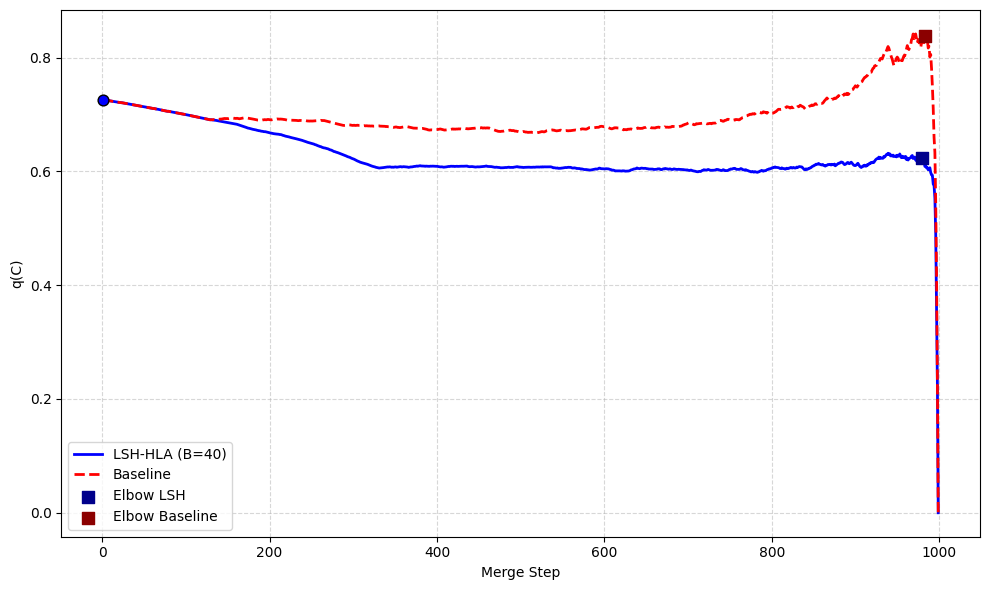

In [17]:
# ----------------------------------------------------
# 5. Visualización de Curvas de Calidad q(C)
# ----------------------------------------------------

df_normal["merge"] = range(1, len(df_normal) + 1)
df_lsh["merge"] = range(1, len(df_lsh) + 1)

idx_max_lsh = df_lsh["q"].idxmax()
x_max_lsh = df_lsh.loc[idx_max_lsh, "merge"]
y_max_lsh = df_lsh.loc[idx_max_lsh, "q"]

idx_max_base = df_normal["q"].idxmax()
x_max_base = df_normal.loc[idx_max_base, "merge"]
y_max_base = df_normal.loc[idx_max_base, "q"]

plt.figure(figsize=(10, 6))

plt.plot(df_lsh["merge"], df_lsh["q"], color="blue", label="LSH-HLA (B=40)", linewidth=2)
plt.plot(df_normal["merge"], df_normal["q"], color="red", linestyle="--", label="Baseline", linewidth=2)

plt.scatter(x_max_lsh, y_max_lsh, color="blue", zorder=5, s=60, edgecolors="black")
#plt.scatter(x_max_base, y_max_base, color="red", zorder=5, s=60, edgecolors="black")

# Anotaciones
plt.scatter(k_star_lsh, df_lsh.loc[k_star_lsh - 1, "q"], color="darkblue", marker="s", s=80, zorder=6, label="Elbow LSH")
plt.scatter(k_star_normal, df_normal.loc[k_star_normal - 1, "q"], color="darkred", marker="s", s=80, zorder=6, label="Elbow Baseline")

plt.xlabel("Merge Step")
plt.ylabel("q(C)")
#plt.title("Comparativa de la Función de Calidad q(C) en SNAP Temporal Email", fontsize=12, fontweight="bold")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(loc="lower left")

plt.tight_layout()
plt.show()


In [11]:
def show_temporal_clusters(labels, method_name):
    print(f"\nClusters de ventanas horarias ({method_name})")
    for cluster_id in sorted(set(labels)):
        members = np.flatnonzero(labels == cluster_id)
        phases = [(int(graphs[i].graph['day']), int(graphs[i].graph['hour'])) for i in members]
        print(f"Cluster {cluster_id}: {len(members)} capas; (día relativo, hora relativa): {phases}")
show_temporal_clusters(labels_baseline, "Baseline")
show_temporal_clusters(labels_lsh, "LSH-HLA")


Clusters de ventanas horarias (Baseline)
Cluster 0: 1 capas; (día relativo, hora relativa): [(8, 18)]
Cluster 1: 1 capas; (día relativo, hora relativa): [(21, 6)]
Cluster 2: 1 capas; (día relativo, hora relativa): [(24, 5)]
Cluster 3: 1 capas; (día relativo, hora relativa): [(25, 6)]
Cluster 4: 1 capas; (día relativo, hora relativa): [(34, 16)]
Cluster 5: 1 capas; (día relativo, hora relativa): [(45, 22)]
Cluster 6: 1 capas; (día relativo, hora relativa): [(66, 15)]
Cluster 7: 1 capas; (día relativo, hora relativa): [(84, 16)]
Cluster 8: 1 capas; (día relativo, hora relativa): [(85, 20)]
Cluster 9: 1 capas; (día relativo, hora relativa): [(90, 5)]
Cluster 10: 1 capas; (día relativo, hora relativa): [(96, 16)]
Cluster 11: 7 capas; (día relativo, hora relativa): [(9, 17), (10, 13), (11, 21), (12, 11), (33, 14), (40, 10), (55, 12)]
Cluster 12: 3 capas; (día relativo, hora relativa): [(40, 19), (43, 23), (50, 18)]
Cluster 13: 2 capas; (día relativo, hora relativa): [(21, 17), (31, 16)]
Cl

## Interpretación temporal, actividad y departamentos
El mapa día × hora muestra los clusters como categorías: gris indica horas sin interacciones y blanco posiciones fuera del intervalo. Los IDs de clusters son propios de cada método; un mismo número no implica correspondencia entre baseline y LSH.

Los perfiles departamentales describen los clusters, no son clases predichas. Se cuenta una participación por extremo de cada interacción: un mensaje entre departamentos aporta una a cada uno. Se compara el promedio de proporciones por hora con la proporción ponderada por actividad, incluyendo Otros en el denominador. Sin asignaciones verificadas se omite esta figura.

La tabla por capa incluye usuarios activos, conexiones distintas, interacciones, densidad sobre el conjunto global de usuarios, cobertura de etiquetas entre usuarios activos y departamento conocido predominante (con empates explícitos). Su proporción se calcula sobre toda la participación, incluida Otros. Las interacciones con algún extremo Otros se contabilizan aparte; no se atribuyen a comunicación interna o entre departamentos.

Se exportan figuras PNG y tablas CSV en `data/TemporalEmail/resultados_dept1/analisis_temporal/`.



Actividad por cluster — baseline
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0             1           2.000000                 1.0           1.000000    1.000000      0.000021                  1.0                    1.0                    0.0                              0.0
1             1           2.000000                 1.0           1.000000    1.000000      0.000021                  1.0                    1.0                    0.0                              0.0
2             1           3.000000                 2.0           2.000000    2.000000      0.000042                  1.0                    2.0                    0.0

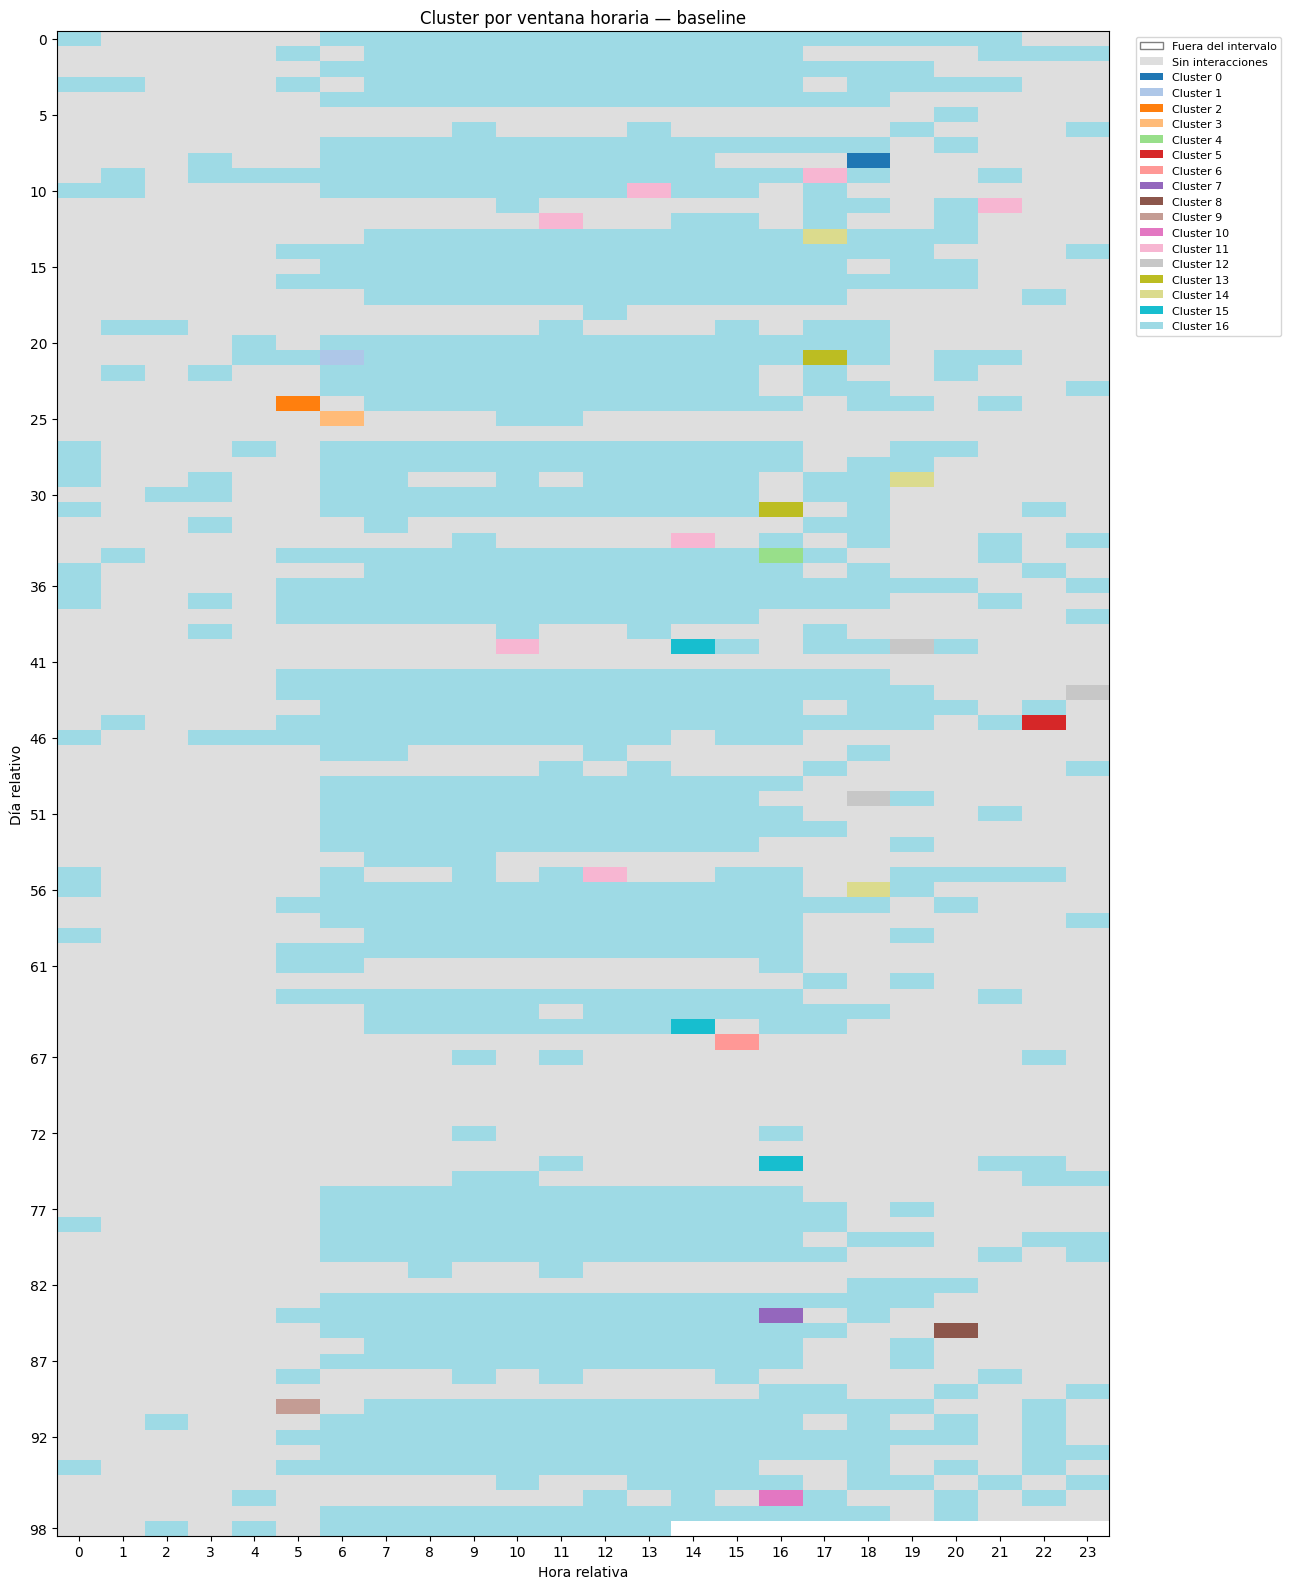

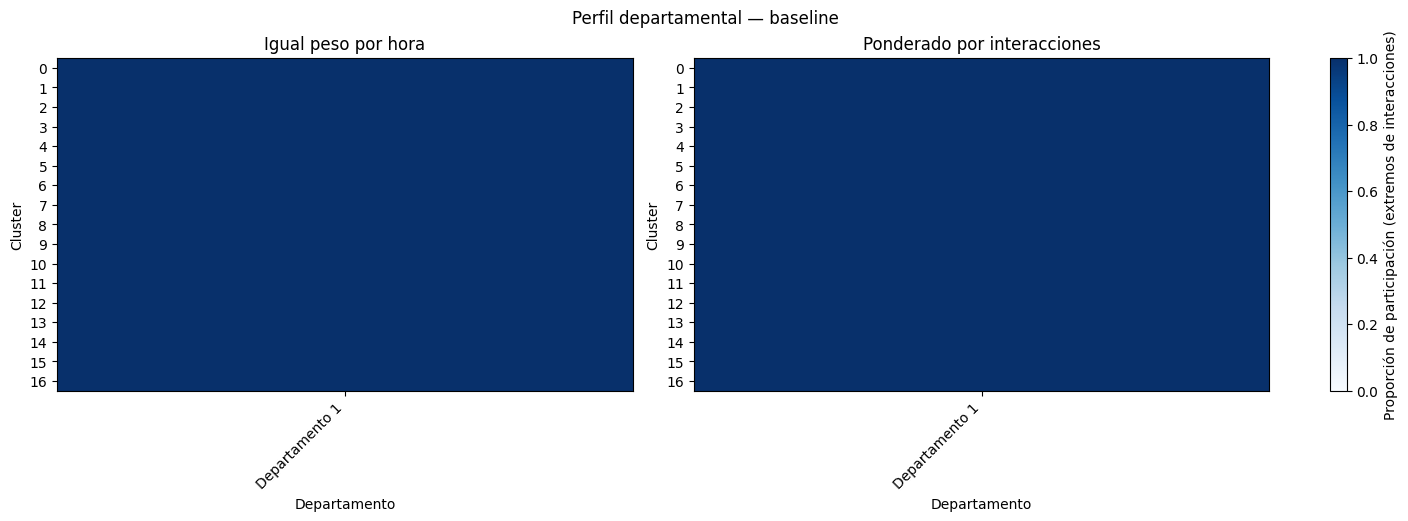


Actividad por cluster — lsh
         layers  mean_active_users  total_interactions  mean_interactions  mean_edges  mean_density  mean_label_coverage  internal_interactions  external_interactions  unknown_department_interactions
cluster                                                                                                                                                                                                
0             1          13.000000                17.0          17.000000    7.000000      0.000147                  1.0                   17.0                    0.0                              0.0
1             1          11.000000                 7.0           7.000000    6.000000      0.000126                  1.0                    7.0                    0.0                              0.0
2             1           8.000000                 5.0           5.000000    5.000000      0.000105                  1.0                    5.0                    0.0     

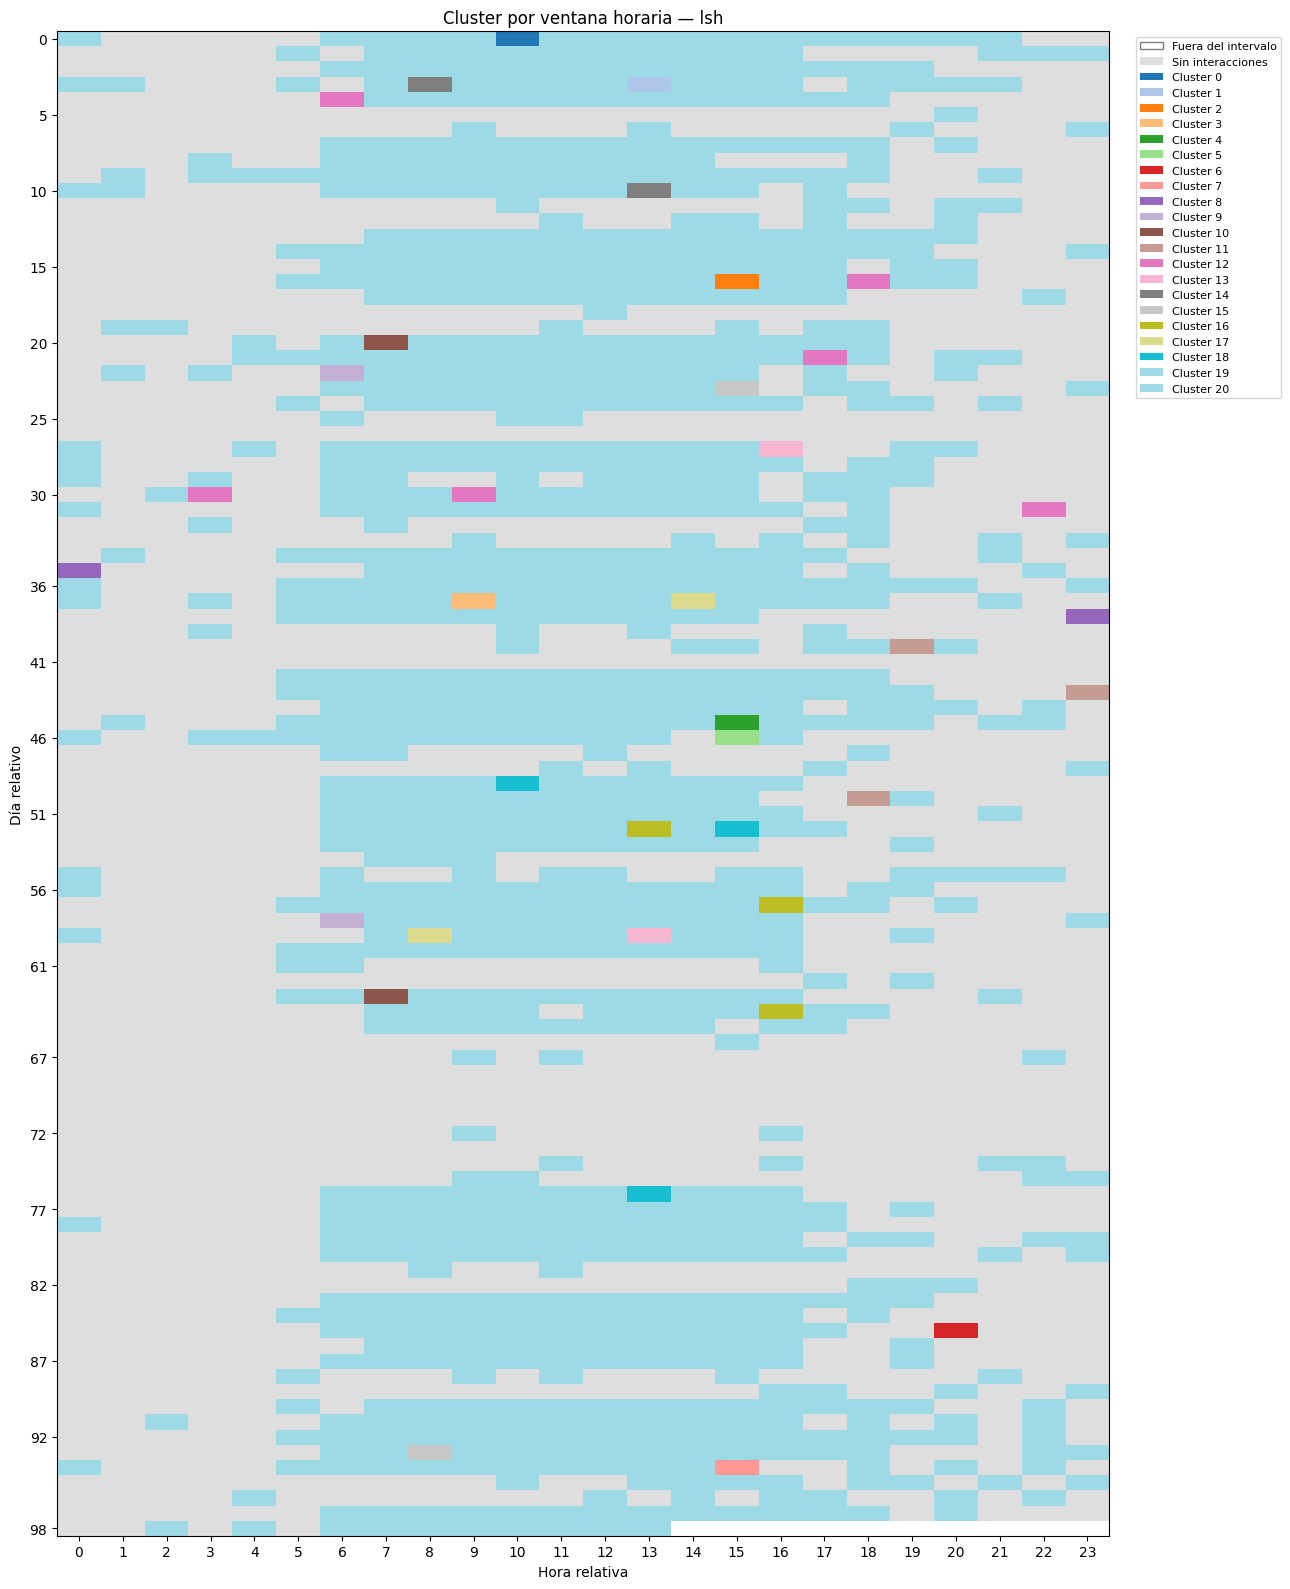

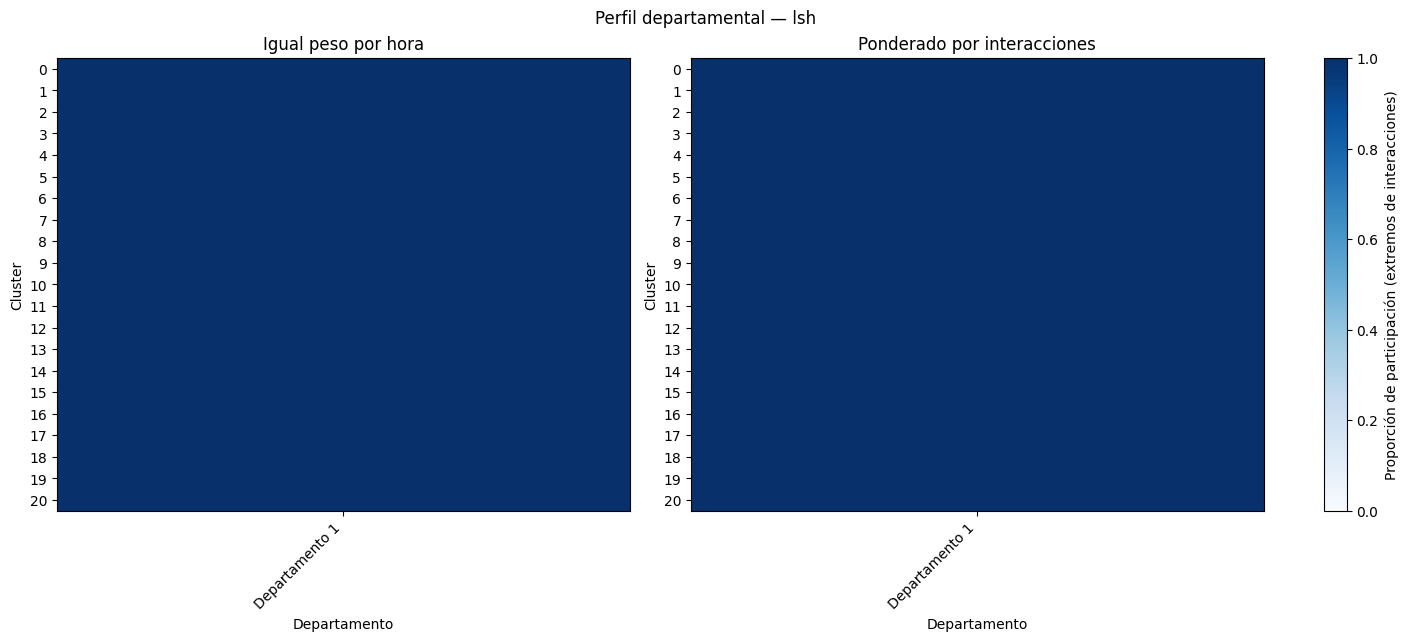

In [12]:
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch


def layer_activity_table(graphs, labels):
    """Department participation counts message endpoints (two per interaction)."""
    if len(graphs) != len(labels):
        raise ValueError("Se requiere una etiqueta por capa")
    rows, profiles = [], []
    for layer, (g, cluster) in enumerate(zip(graphs, labels)):
        active = [u for u, degree in g.degree() if degree > 0]
        departments = {u: str(g.nodes[u].get('departamento', 'Otros')).strip() or 'Otros'
                       for u in active}
        participation = defaultdict(float)
        events = internal = external = unknown = 0.0
        for u, v, data in g.edges(data=True):
            w = float(data.get('weight', 1))
            events += w
            a, b = departments[u], departments[v]
            participation[a] += w
            participation[b] += w
            if 'Otros' in (a, b):
                unknown += w
            elif a == b:
                internal += w
            else:
                external += w
        total = sum(participation.values())
        known = {d: w for d, w in participation.items() if d != 'Otros'}
        largest = max(known.values(), default=0)
        winners = sorted(d for d, w in known.items() if w == largest)
        dominant = winners[0] if len(winners) == 1 else ('Empate' if winners else 'Sin asignación')
        rows.append(dict(layer=layer, day=int(g.graph['day']), hour=int(g.graph['hour']),
                         cluster=int(cluster), active_users=len(active), interactions=events,
                         edges=g.number_of_edges(),
                         density=nx.density(g),
                         label_coverage=sum(d != 'Otros' for d in departments.values()) / len(active) if active else 0,
                         dominant_department=dominant,
                         dominant_share=largest / total if total else 0,
                         internal_interactions=internal, external_interactions=external,
                         unknown_department_interactions=unknown))
        for department, weight in participation.items():
            profiles.append(dict(layer=layer, cluster=int(cluster), department=department,
                                 participation=weight, share=weight / total if total else 0))
    return pd.DataFrame(rows), pd.DataFrame(profiles)


def temporal_cluster_grid(table, start_hour, end_hour):
    """-2 outside interval; -1 empty hour; nonnegative categorical cluster codes."""
    first_day, last_day = start_hour // 24, (end_hour - 1) // 24
    hours = np.arange(first_day * 24, (last_day + 1) * 24).reshape(-1, 24)
    grid = np.where((hours >= start_hour) & (hours < end_hour), -1, -2)
    cluster_ids = sorted(table.cluster.unique())
    codes = {cluster: i for i, cluster in enumerate(cluster_ids)}
    for row in table.itertuples():
        grid[row.day - first_day, row.hour] = codes[row.cluster]
    return grid, first_day, cluster_ids


def plot_temporal_analysis(graphs, labels, method, selection, output_dir):
    output_dir = Path(output_dir)
    output_dir.mkdir(parents=True, exist_ok=True)
    table, profiles = layer_activity_table(graphs, labels)
    table.to_csv(output_dir / f'{method}_capas.csv', index=False)
    summary = table.groupby('cluster').agg(
        layers=('layer', 'size'), mean_active_users=('active_users', 'mean'),
        total_interactions=('interactions', 'sum'), mean_interactions=('interactions', 'mean'),
        mean_edges=('edges', 'mean'), mean_density=('density', 'mean'),
        mean_label_coverage=('label_coverage', 'mean'),
        internal_interactions=('internal_interactions', 'sum'),
        external_interactions=('external_interactions', 'sum'),
        unknown_department_interactions=('unknown_department_interactions', 'sum'))
    summary.to_csv(output_dir / f'{method}_clusters.csv')
    print(f'\nActividad por cluster — {method}')
    print(summary.to_string())

    grid, first_day, cluster_ids = temporal_cluster_grid(
        table, selection['start_hour'], selection['end_hour_exclusive'])
    palette = plt.get_cmap('tab20', max(1, len(cluster_ids)))
    colors = ['white', '#dedede'] + [palette(i) for i in range(len(cluster_ids))]
    cmap = ListedColormap(colors)
    norm = BoundaryNorm(np.arange(-2.5, len(cluster_ids) + .5), len(colors))
    fig, ax = plt.subplots(figsize=(13, max(5, min(16, len(grid) * .18))))
    ax.imshow(grid, cmap=cmap, norm=norm, aspect='auto', interpolation='nearest')
    ticks = np.unique(np.linspace(0, len(grid) - 1, min(20, len(grid)), dtype=int))
    ax.set_yticks(ticks, ticks + first_day)
    ax.set_xticks(range(24))
    ax.set(xlabel='Hora relativa', ylabel='Día relativo', title=f'Cluster por ventana horaria — {method}')
    handles = [Patch(facecolor=colors[0], edgecolor='gray', label='Fuera del intervalo'),
               Patch(facecolor=colors[1], label='Sin interacciones')]
    handles += [Patch(facecolor=colors[i + 2], label=f'Cluster {c}') for i, c in enumerate(cluster_ids)]
    ax.legend(handles=handles, bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
    fig.tight_layout()
    fig.savefig(output_dir / f'{method}_dia_hora.png', dpi=180, bbox_inches='tight')
    plt.show()

    if profiles.empty or not (profiles.department != 'Otros').any():
        print('Perfil departamental omitido: no hay departamentos verificados; todas las etiquetas son Otros.')
        return table, summary

    # Fill missing layer/department combinations with zero before averaging.
    shares = profiles.pivot(index='layer', columns='department', values='share').fillna(0)
    hourly = shares.groupby(table.set_index('layer')['cluster']).mean()
    totals = profiles.groupby(['cluster', 'department']).participation.sum().unstack(fill_value=0)
    weighted = totals.div(totals.sum(axis=1), axis=0)
    weighted = weighted.reindex(index=hourly.index, columns=hourly.columns, fill_value=0)
    hourly.to_csv(output_dir / f'{method}_departamentos_promedio_hora.csv')
    weighted.to_csv(output_dir / f'{method}_departamentos_ponderados.csv')
    fig, axes = plt.subplots(1, 2, figsize=(14, max(4, len(hourly) * .3)), constrained_layout=True)
    for ax, matrix, title in zip(axes, [hourly, weighted],
                                ['Igual peso por hora', 'Ponderado por interacciones']):
        im = ax.imshow(matrix.values, vmin=0, vmax=1, cmap='Blues', aspect='auto')
        ax.set_xticks(range(len(matrix.columns)), matrix.columns, rotation=45, ha='right')
        ax.set_yticks(range(len(matrix)), matrix.index)
        ax.set(title=title, xlabel='Departamento', ylabel='Cluster')
    fig.colorbar(im, ax=axes, label='Proporción de participación (extremos de interacciones)')
    fig.suptitle(f'Perfil departamental — {method}')
    fig.savefig(output_dir / f'{method}_cluster_departamento.png', dpi=180, bbox_inches='tight')
    plt.show()
    return table, summary


analysis_output_dir = Path('data/TemporalEmail/resultados_dept1/analisis_temporal')
activity_baseline, summary_baseline = plot_temporal_analysis(
    graphs, labels_baseline, 'baseline', selection_metadata, analysis_output_dir)
activity_lsh, summary_lsh = plot_temporal_analysis(
    graphs, labels_lsh, 'lsh', selection_metadata, analysis_output_dir)


## Estabilidad y sensibilidad
Diez repeticiones por configuración, con semilla explícita por corrida y cachés vacías antes de cada cronómetro. Se reporta desviación estándar muestral (ddof=1). Las etiquetas se conservan para medir concordancia entre corridas; ARI/NMI frente al baseline comparan cortes seleccionados por el codo. El tiempo excluye carga, copia de grafos y evaluación posterior. La moda del tiempo no se interpreta como rendimiento típico.


In [13]:
from collections import Counter

def calculate_mode(values):
    rounded_vals = [round(v, 2) if isinstance(v, float) else v for v in values]
    counts = Counter(rounded_vals)
    mode_val, _ = counts.most_common(1)[0]
    return mode_val


In [14]:
NUM_RUNS_TEMP = 10
NUM_PROJ_FIXED_TEMP = 5
B_FIXED_TEMP = 40
num_graphs_temp = len(graphs)

run_data_temp = []
run_labels_temp = []

print(f"Ejecutando {NUM_RUNS_TEMP} corridas de LSH-HLA sobre la red temporal SNAP...")
# Semillas para reproducibilidad global de la serie
np.random.seed(42)
random.seed(42)

for r in tqdm(range(NUM_RUNS_TEMP), desc="Corridas Temporal"):
    run_graphs = fresh_graphs(graphs)
    np.random.seed(42 + r)
    random.seed(42 + r)
    start_time = time.perf_counter()
    Z_B, _, _, _, bucket_ids = shclust_heap_dynamic(
        run_graphs,
        num_proj=NUM_PROJ_FIXED_TEMP,
        B=B_FIXED_TEMP,
        epsilon=np.inf
    )
    elapsed = time.perf_counter() - start_time
    
    # Calcular paso de codo y número de clusters
    df_B = pd.DataFrame(
        Z_B,
        columns=[
            "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
            "new_bucket_id", "same_bucket", "global_mode"
        ]
    )
    k_star, _ = elbow_method(df_B["q"].values)
    num_clusters = df_B.shape[0] - k_star + 1
    unique_buckets = len(set(bucket_ids))
    run_labels_temp.append(get_cluster_labels(Z_B, len(graphs), k_star))
    
    run_data_temp.append({
        "Corrida": r + 1,
        "Semilla": 42 + r,
        "Buckets Únicos": unique_buckets,
        "Paso de Fusión (k*)": k_star,
        "Clusters seleccionados": num_clusters,
        "Tiempo (seg)": elapsed,
        "ARI vs baseline": adjusted_rand_score(labels_baseline, get_cluster_labels(Z_B, len(graphs), k_star)),
        "NMI vs baseline": normalized_mutual_info_score(labels_baseline, get_cluster_labels(Z_B, len(graphs), k_star))
    })

df_stability_temp = pd.DataFrame(run_data_temp)
print("\n=== ESTABILIDAD DE LSH-HLA SOBRE SNAP TEMPORAL (10 Corridas) ===")
print(df_stability_temp.to_string(index=False))

print("\n=== ESTADÍSTICAS GLOBALES SNAP TEMPORAL (Media ± Desv. Estándar) ===")
stats_summary_temp = pd.DataFrame({
    "Métrica": ["Buckets Únicos", "Paso de Fusión (k*)", "Clusters seleccionados", "Tiempo (seg)"],
    "Promedio": [
        df_stability_temp["Buckets Únicos"].mean(),
        df_stability_temp["Paso de Fusión (k*)"].mean(),
        df_stability_temp["Clusters seleccionados"].mean(),
        df_stability_temp["Tiempo (seg)"].mean()
    ],
    "Desv. Estándar": [
        df_stability_temp["Buckets Únicos"].std(),
        df_stability_temp["Paso de Fusión (k*)"].std(),
        df_stability_temp["Clusters seleccionados"].std(),
        df_stability_temp["Tiempo (seg)"].std()
    ]
})
print(stats_summary_temp.to_string(index=False))
# Concordancia de membresías entre todas las parejas de corridas.
pairwise_stability = pd.DataFrame([
    {"Run_A": i + 1, "Run_B": j + 1,
     "ARI": adjusted_rand_score(a, run_labels_temp[j]),
     "NMI": normalized_mutual_info_score(a, run_labels_temp[j])}
    for i, a in enumerate(run_labels_temp) for j in range(i + 1, len(run_labels_temp))
])
print(pairwise_stability[["ARI", "NMI"]].agg(["mean", "std", "min", "max"]))
output_dir = Path("data/TemporalEmail/resultados_dept1")
output_dir.mkdir(exist_ok=True)
df_stability_temp.to_csv(output_dir / "estabilidad_lsh.csv", index=False)
np.save(output_dir / "membresias_lsh.npy", np.asarray(run_labels_temp))
pairwise_stability.to_csv(output_dir / "concordancia_entre_corridas.csv", index=False)

baseline_runs = []
for r in range(NUM_RUNS_TEMP):
    run_graphs = fresh_graphs(graphs)
    start_time = time.perf_counter()
    z, _, _ = hierarchical_clustering_heap(run_graphs)
    elapsed = time.perf_counter() - start_time
    cut, _ = elbow_method([row[3] for row in z])
    baseline_runs.append({"Corrida": r + 1, "Tiempo": elapsed, "Clusters": len(graphs) - cut})
df_baseline_runs = pd.DataFrame(baseline_runs)
print(df_baseline_runs[["Tiempo", "Clusters"]].agg(["mean", "std"]))
df_baseline_runs.to_csv(output_dir / "baseline.csv", index=False)


Ejecutando 10 corridas de LSH-HLA sobre la red temporal SNAP...


Acumulando matrices de densidad: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 12740.74it/s]

Buscando vecinos iniciales (memoria lineal): 100%|██████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:04<00:00, 220.60it/s]

Acumulando matrices de densidad: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 1000/1000 [00:00<00:00, 12464.50it/s]

Buscando vecinos iniciales (memoria lineal): 100%|█████████████████


=== ESTABILIDAD DE LSH-HLA SOBRE SNAP TEMPORAL (10 Corridas) ===
 Corrida  Semilla  Buckets Únicos  Paso de Fusión (k*)  Clusters seleccionados  Tiempo (seg)  ARI vs baseline  NMI vs baseline
       1       42             669                  979                      21   2074.449524         0.142666         0.150642
       2       43             646                  989                      11   2003.596617         0.277869         0.286699
       3       44             685                  990                      10   2070.820020         0.018842         0.027425
       4       45             656                  949                      51   1972.528605         0.103997         0.118835
       5       46             674                  974                      26   2156.338060         0.153379         0.137924
       6       47             683                  982                      18   2132.511170         0.005599         0.033110
       7       48             667            

Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [44:35<00:00,  2.68s/it]

           Tiempo  Clusters
mean  3245.583028      17.0
std      8.474128       0.0


Evaluando análisis de sensibilidad sobre B (10 ejecuciones por valor)...
Evaluando B = 10...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [29:16<00:00,  1.76s/it]


Evaluando B = 40...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [33:28<00:00,  2.01s/it]


Evaluando B = 80...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [34:00<00:00,  2.04s/it]


Evaluando B = 300...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [33:57<00:00,  2.04s/it]



=== REPORTE DE SENSIBILIDAD DE B SOBRE SNAP TEMPORAL (10 ejecuciones por valor) ===
  B  ARI_Mean  ARI_Std  NMI_Mean  NMI_Std  Buckets_Mean  Buckets_Std  Buckets_Mode  KStar_Mean  KStar_Std  KStar_Mode  Clusters_Mean  Clusters_Std  Clusters_Mode   Time_Mean  Time_Std  Time_Mode
 10  0.149858 0.098601  0.148327 0.085507         595.7    22.281283           588       981.7   6.864563         982           18.3      6.864563             18 1694.771486 66.731346    1676.67
 40  0.127295 0.110372  0.136566 0.096422         671.4    13.284912           669       978.9  12.564942         990           21.1     12.564942             10 2018.359220 49.003438    2046.18
 80  0.130166 0.107955  0.138998 0.094766         671.8    13.130118           669       978.8  12.263768         990           21.2     12.263768             10 2018.116669 47.292312    2027.78
300  0.130166 0.107955  0.138998 0.094766         671.8    13.130118           669       978.8  12.263768         990           21.2   

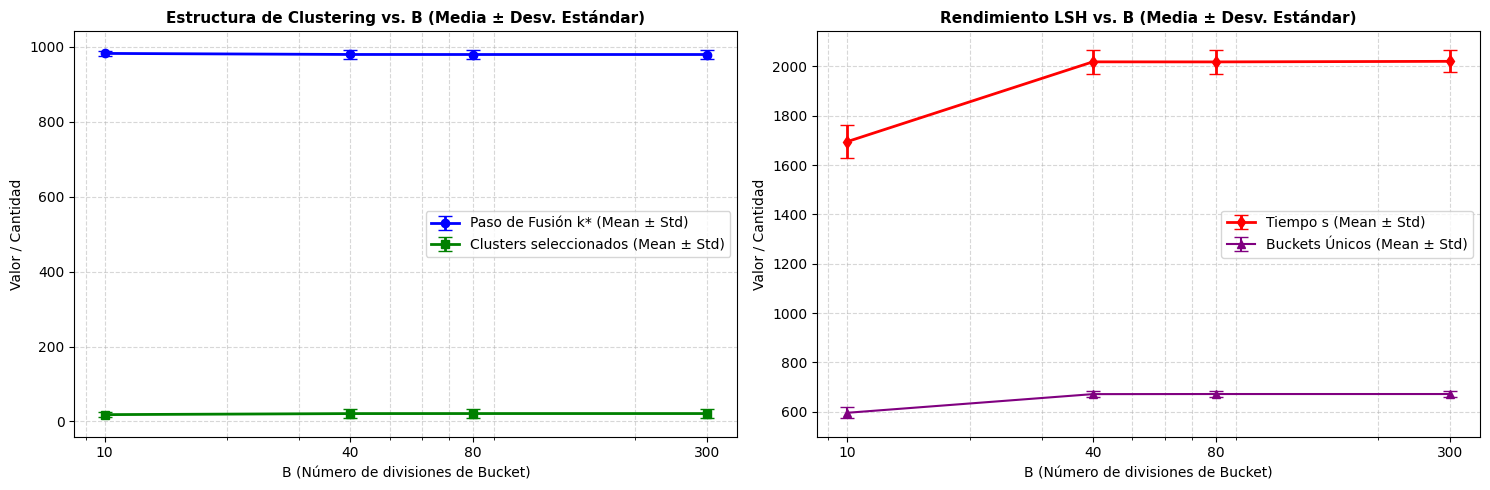

In [15]:
B_values_temp = [10, 40, 80, 300]
NUM_PROJ_SENSITIVITY_TEMP = 5
REPS_PER_B_TEMP = 10

sensitivity_results_temp = []

print("Evaluando análisis de sensibilidad sobre B (10 ejecuciones por valor)...")
# Semilla para reproducibilidad
np.random.seed(42)
random.seed(42)

for B_val in B_values_temp:
    print(f"Evaluando B = {B_val}...")
    temp_buckets = []
    temp_kstar = []
    temp_clusters = []
    temp_time = []
    temp_ari = []
    temp_nmi = []
    
    for _ in range(REPS_PER_B_TEMP):
        run_graphs = fresh_graphs(graphs)
        np.random.seed(42 + _)
        random.seed(42 + _)
        start_time = time.perf_counter()
        Z_B, _, _, _, bucket_ids = shclust_heap_dynamic(
            run_graphs,
            num_proj=NUM_PROJ_SENSITIVITY_TEMP,
            B=B_val,
            epsilon=np.inf
        )
        elapsed = time.perf_counter() - start_time
        
        df_B = pd.DataFrame(
            Z_B,
            columns=[
                "cluster_i", "cluster_j", "dist", "q", "new_cluster_id",
                "new_bucket_id", "same_bucket", "global_mode"
            ]
        )
        k_star, _ = elbow_method(df_B["q"].values)
        num_clusters = df_B.shape[0] - k_star + 1
        unique_buckets = len(set(bucket_ids))
        
        temp_buckets.append(unique_buckets)
        temp_kstar.append(k_star)
        temp_clusters.append(num_clusters)
        temp_time.append(elapsed)
        labels = get_cluster_labels(Z_B, len(graphs), k_star)
        temp_ari.append(adjusted_rand_score(labels_baseline, labels))
        temp_nmi.append(normalized_mutual_info_score(labels_baseline, labels))
        
    sensitivity_results_temp.append({
        "B": B_val,
        "ARI_Mean": np.mean(temp_ari),
        "ARI_Std": np.std(temp_ari, ddof=1),
        "NMI_Mean": np.mean(temp_nmi),
        "NMI_Std": np.std(temp_nmi, ddof=1),
        
        "Buckets_Mean": np.mean(temp_buckets),
        "Buckets_Std": np.std(temp_buckets, ddof=1),
        "Buckets_Mode": calculate_mode(temp_buckets),
        
        "KStar_Mean": np.mean(temp_kstar),
        "KStar_Std": np.std(temp_kstar, ddof=1),
        "KStar_Mode": calculate_mode(temp_kstar),
        
        "Clusters_Mean": np.mean(temp_clusters),
        "Clusters_Std": np.std(temp_clusters, ddof=1),
        "Clusters_Mode": calculate_mode(temp_clusters),
        
        "Time_Mean": np.mean(temp_time),
        "Time_Std": np.std(temp_time, ddof=1),
        "Time_Mode": calculate_mode(temp_time)
    })

# Convertir a DataFrame y presentar reporte
df_sensitivity_temp = pd.DataFrame(sensitivity_results_temp)
print("\n=== REPORTE DE SENSIBILIDAD DE B SOBRE SNAP TEMPORAL (10 ejecuciones por valor) ===")
print(df_sensitivity_temp.to_string(index=False))

# ----------------------------------------------------
# Visualización de Sensibilidad SNAP con Barras de Error
# ----------------------------------------------------
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Subplot 1: Paso de Fusión y Número de Clusters
ax1.errorbar(df_sensitivity_temp["B"], df_sensitivity_temp["KStar_Mean"], yerr=df_sensitivity_temp["KStar_Std"], 
             marker='o', label="Paso de Fusión k* (Mean ± Std)", color="blue", linewidth=2, capsize=5)
ax1.errorbar(df_sensitivity_temp["B"], df_sensitivity_temp["Clusters_Mean"], yerr=df_sensitivity_temp["Clusters_Std"], 
             marker='s', label="Clusters seleccionados (Mean ± Std)", color="green", linewidth=2, capsize=5)

ax1.set_xscale('log')
ax1.set_xticks(B_values_temp)
ax1.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax1.set_title("Estructura de Clustering vs. B (Media ± Desv. Estándar)", fontsize=11, fontweight='bold')
ax1.set_xlabel("B (Número de divisiones de Bucket)")
ax1.set_ylabel("Valor / Cantidad")
ax1.grid(True, which="both", linestyle="--", alpha=0.5)
ax1.legend()

# Subplot 2: Tiempo de corrida y Buckets Únicos
ax2.errorbar(df_sensitivity_temp["B"], df_sensitivity_temp["Time_Mean"], yerr=df_sensitivity_temp["Time_Std"], 
             marker='d', color="red", linewidth=2, capsize=5, label="Tiempo s (Mean ± Std)")
ax2.errorbar(df_sensitivity_temp["B"], df_sensitivity_temp["Buckets_Mean"], yerr=df_sensitivity_temp["Buckets_Std"], 
             marker='^', color="purple", linewidth=1.5, capsize=5, label="Buckets Únicos (Mean ± Std)")
ax2.set_xscale('log')
ax2.set_xticks(B_values_temp)
ax2.get_xaxis().set_major_formatter(plt.ScalarFormatter())
ax2.set_title("Rendimiento LSH vs. B (Media ± Desv. Estándar)", fontsize=11, fontweight='bold')
ax2.set_xlabel("B (Número de divisiones de Bucket)")
ax2.set_ylabel("Valor / Cantidad")
ax2.grid(True, which="both", linestyle="--", alpha=0.5)
ax2.legend()

plt.tight_layout()
plt.show()
Path("data/TemporalEmail/resultados_dept1").mkdir(exist_ok=True)
df_sensitivity_temp.to_csv("data/TemporalEmail/resultados_dept1/sensibilidad.csv", index=False)


B=10: calculando una corrida con semilla 42...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [28:04<00:00,  1.69s/it]

B=40: reutilizando la corrida individual de esta sesión.
B=80: calculando una corrida con semilla 42...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [33:56<00:00,  2.04s/it]

B=300: calculando una corrida con semilla 42...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [33:55<00:00,  2.04s/it]


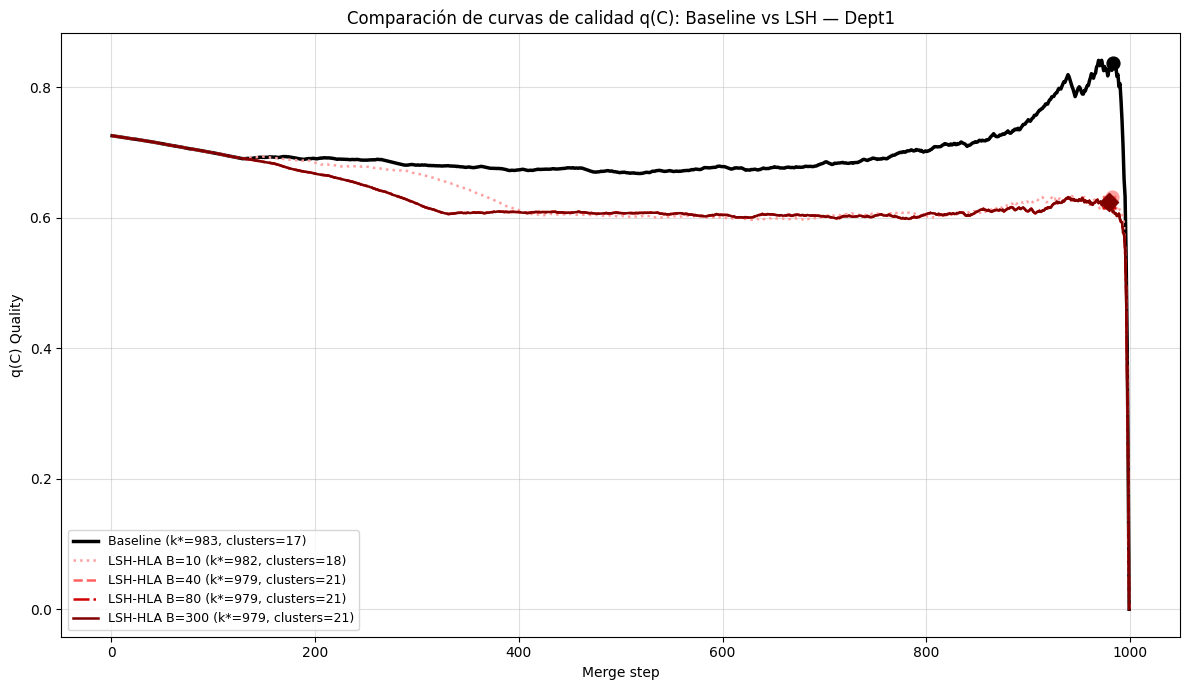

  Method     B  k_star  Selected_clusters  q_at_cut
Baseline   NaN     983                 17  0.837782
 LSH-HLA  10.0     982                 18  0.631622
 LSH-HLA  40.0     979                 21  0.624081
 LSH-HLA  80.0     979                 21  0.624081
 LSH-HLA 300.0     979                 21  0.624081
Figura: una corrida por B, semilla 42; no representa promedios de diez corridas.


In [18]:
# Comparación q(C): baseline y LSH variando B (una corrida, semilla 42).
# Reutiliza Z_baseline y Z_lsh de esta sesión; calcula solo las otras B que falten.
# Los CSV de sensibilidad contienen resúmenes, no las trayectorias completas.
import hashlib
from pathlib import Path

if 'graphs' not in globals() or 'Z_baseline' not in globals():
    raise RuntimeError('Ejecuta primero la carga y el baseline para el conjunto de grafos actual.')

comparison_seed = 42
comparison_projections = 5
comparison_B_values = [10, 40, 80, 300]
comparison_dir = Path('data/TemporalEmail/resultados_dept1/curvas_calidad')
comparison_dir.mkdir(parents=True, exist_ok=True)

# Identifica datos, pesos y orden de las capas para no mezclar intervalos.
fingerprint = hashlib.sha256(b'dept1-quality-v1-seed42-projections5')
for graph in graphs:
    fingerprint.update(repr((tuple(sorted(graph.nodes())), graph.graph.get('absolute_hour'))).encode())
    edges = sorted((min(u, v), max(u, v), float(d.get('weight', 1)))
                   for u, v, d in graph.edges(data=True))
    fingerprint.update(repr(edges).encode())
cache_key = fingerprint.hexdigest()[:20]
# Cambia a True si modificas el algoritmo y deseas recalcular las curvas LSH.
RECOMPUTE_LSH_CURVES = False

q_baseline_comparison = np.asarray([row[3] for row in Z_baseline], dtype=float)
if len(q_baseline_comparison) != len(graphs) - 1:
    raise ValueError('La jerarquía baseline no está completa o corresponde a otro número de capas.')
q_lsh_comparison = {}
for B_plot in comparison_B_values:
    cache_file = comparison_dir / f'{cache_key}_B{B_plot}.npy'
    if cache_file.exists() and not RECOMPUTE_LSH_CURVES:
        q_values = np.load(cache_file, allow_pickle=False)
        print(f'B={B_plot}: curva recuperada del disco.')
    elif B_plot == 40 and 'Z_lsh' in globals() and not RECOMPUTE_LSH_CURVES:
        # Z_lsh es la corrida B=40, cinco proyecciones, semilla 42 de la celda 10.
        q_values = np.asarray([row[3] for row in Z_lsh], dtype=float)
        print('B=40: reutilizando la corrida individual de esta sesión.')
    else:
        print(f'B={B_plot}: calculando una corrida con semilla {comparison_seed}...', flush=True)
        numpy_state, python_state = np.random.get_state(), random.getstate()
        try:
            np.random.seed(comparison_seed)
            random.seed(comparison_seed)
            z_plot, _, _, _, _ = shclust_heap_dynamic(
                fresh_graphs(graphs), num_proj=comparison_projections,
                B=B_plot, proj_func=projection_frobenius, epsilon=np.inf)
            q_values = np.asarray([row[3] for row in z_plot], dtype=float)
            del z_plot
        finally:
            np.random.set_state(numpy_state)
            random.setstate(python_state)
    if q_values.shape != (len(graphs) - 1,) or not np.isfinite(q_values).all():
        raise ValueError(f'Curva inválida o incompleta para B={B_plot}.')
    np.save(cache_file, q_values)
    q_lsh_comparison[B_plot] = q_values

red_styles = {
    10: ('#ffa0a0', ':', 'o'),
    40: ('#ff6060', '--', 's'),
    80: ('#d00000', '-.', '^'),
    300: ('#800000', '-', 'D'),
}
fig, ax = plt.subplots(figsize=(12, 7))
comparison_rows = []
comparison_curves = [('Baseline', None, q_baseline_comparison, 'black', '-', 'o')]
comparison_curves += [('LSH-HLA', B, q_lsh_comparison[B], *red_styles[B]) for B in comparison_B_values]
for method, B_plot, q_values, color, style, marker in comparison_curves:
    cut, _ = elbow_method(q_values)
    count = len(graphs) - cut
    label = method if B_plot is None else f'{method} B={B_plot}'
    ax.plot(np.arange(1, len(q_values) + 1), q_values, color=color,
            linestyle=style, linewidth=2.5 if B_plot is None else 1.8,
            label=f'{label} (k*={cut}, clusters={count})')
    ax.scatter(cut, q_values[cut - 1], color=color, marker=marker, s=85, zorder=5)
    comparison_rows.append({'Method': method, 'B': B_plot, 'k_star': cut,
                            'Selected_clusters': count, 'q_at_cut': q_values[cut - 1]})
ax.set(xlabel='Merge step', ylabel='q(C) Quality',
       title='Comparación de curvas de calidad q(C): Baseline vs LSH — Dept1')
ax.legend(fontsize=9)
ax.grid(True, alpha=.4)
fig.tight_layout()
fig.savefig(comparison_dir / 'compare_qualities_dept1.png', dpi=200, bbox_inches='tight')
fig.savefig(comparison_dir / 'compare_qualities_dept1.pdf', bbox_inches='tight')
plt.show()
pd.DataFrame(comparison_rows).to_csv(comparison_dir / 'elbow_comparison.csv', index=False)
pd.DataFrame({'merge': np.arange(1, len(graphs)), 'baseline': q_baseline_comparison,
              **{f'LSH_B{B}': q_lsh_comparison[B] for B in comparison_B_values}}).to_csv(
                  comparison_dir / 'quality_trajectories.csv', index=False)
print(pd.DataFrame(comparison_rows).to_string(index=False))
print('Figura: una corrida por B, semilla 42; no representa promedios de diez corridas.')


## Diez corridas B=40: curvas de calidad y tabla detallada
Ejecutar después de las funciones y de la carga de grafos. Esta celda no depende del baseline y utiliza entropía espectral. Reporta clusters seleccionados, paso de agregación del codo, buckets iniciales, q en el codo y tiempo, más media y desviación estándar muestral. No incluye ARI ni NMI.

Las tablas antiguas no guardan las diez trayectorias completas: la primera ejecución calcula las corridas que no tengan un archivo compatible. Cada corrida se guarda para reanudar y las siguientes ejecuciones reutilizan esos resultados. El tiempo recuperado es el de la corrida original. Los resultados se exportan a `data/TemporalEmail/resultados_dept1/diez_corridas_B40/`, separados de Taylor.


Corrida 1/10, B=40, semilla=42...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [35:29<00:00,  2.13s/it]


Corrida 2/10, B=40, semilla=43...


Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [32:49<00:00,  1.97s/it]

Corrida 3/10, B=40, semilla=44...


...

Corrida 9/10, B=40, semilla=50...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [34:53<00:00,  2.10s/it]

Corrida 10/10, B=40, semilla=51...



Fusiones: 100%|████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 999/999 [34:54<00:00,  2.10s/it]


 Corrida  Semilla  B  # Clusters  Aggregation step (k*)  # Buckets iniciales  q en el codo  Tiempo (s)
       1       42 40          21                    979                  669      0.624081 2136.659173
       2       43 40          11                    989                  646      0.699744 1980.103859
       3       44 40          10                    990                  685      0.648097 2035.779703
       4       45 40          51                    949                  656      0.607565 1919.781367
       5       46 40          26                    974                  674      0.614126 2092.858624
       6       47 40          18                    982                  683      0.640022 2050.587493
       7       48 40          18                    982                  667      0.677644 2138.350597
       8       49 40          31                    969                  682      0.628114 2097.207800
       9       50 40          10                    990                  

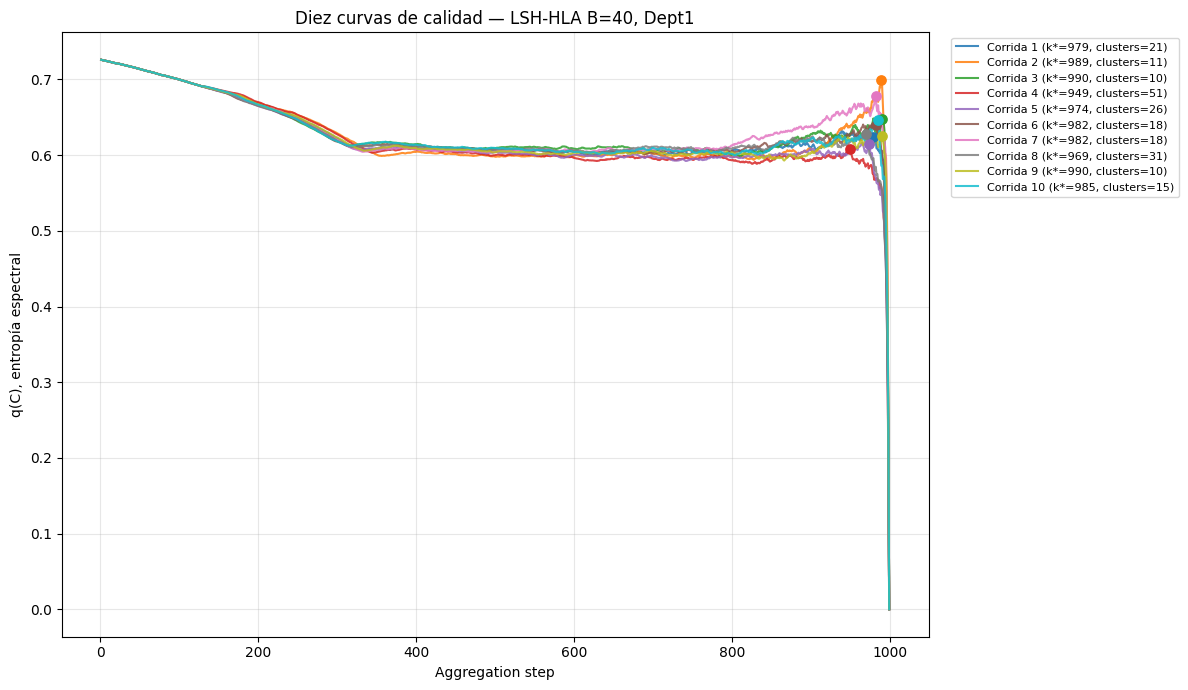

Archivos guardados en: data/TemporalEmail/resultados_dept1/diez_corridas_B40/f5f1643278f4fcf05100
Los marcadores indican el codo de cada corrida; no son necesariamente máximos de q.


In [20]:
# Diez corridas LSH-HLA B=40: tabla y curvas q(C), sin depender del baseline.
import hashlib
import json
from pathlib import Path

NUM_RUNS_TEMP = 10
NUM_PROJ_FIXED_TEMP = 5
B_FIXED_TEMP = 40
FORCE_TEN_RUNS = False  # True recalcula; False reanuda resultados guardados.

# Clave por datos, orden, pesos, implementación y entropía espectral.
notebook_path = Path('shclust-temporal-email-dept1.ipynb')
implementation = ''.join(json.loads(notebook_path.read_text())['cells'][1]['source'])
fingerprint = hashlib.sha256(implementation.encode())
fingerprint.update(repr(('spectral', B_FIXED_TEMP, NUM_PROJ_FIXED_TEMP)).encode())
for g in graphs:
    fingerprint.update(repr((tuple(sorted(g.nodes())), g.graph.get('absolute_hour'),
        sorted((min(u,v), max(u,v), float(d.get('weight',1)))
               for u,v,d in g.edges(data=True)))).encode())
output_dir = Path('data/TemporalEmail/resultados_dept1/diez_corridas_B40') / fingerprint.hexdigest()[:20]
output_dir.mkdir(parents=True, exist_ok=True)
run_data_temp, run_quality_temp = [], []

for r in range(NUM_RUNS_TEMP):
    seed = 42 + r
    checkpoint = output_dir / f'corrida_{r+1:02d}.npz'
    if checkpoint.exists() and not FORCE_TEN_RUNS:
        with np.load(checkpoint, allow_pickle=False) as saved:
            q_values = saved['q'].copy()
            elapsed = float(saved['elapsed'])
            unique_buckets = int(saved['buckets'])
            if int(saved['seed']) != seed:
                raise ValueError('Semilla incompatible en el archivo guardado.')
        print(f'Corrida {r+1}: recuperada del disco (tiempo de la ejecución original).')
    else:
        print(f'Corrida {r+1}/{NUM_RUNS_TEMP}, B=40, semilla={seed}...', flush=True)
        run_graphs = fresh_graphs(graphs)
        numpy_state, python_state = np.random.get_state(), random.getstate()
        try:
            np.random.seed(seed)
            random.seed(seed)
            start_time = time.perf_counter()
            z_run, _, _, _, bucket_ids = shclust_heap_dynamic(
                run_graphs, num_proj=NUM_PROJ_FIXED_TEMP, B=B_FIXED_TEMP, epsilon=np.inf)
            elapsed = time.perf_counter() - start_time
            q_values = np.asarray([row[3] for row in z_run], dtype=float)
            unique_buckets = len(set(bucket_ids))
            del z_run
        finally:
            np.random.set_state(numpy_state)
            random.setstate(python_state)
    if q_values.shape != (len(graphs)-1,) or not np.isfinite(q_values).all():
        raise ValueError(f'Corrida {r+1}: trayectoria incompleta o inválida.')
    cut, _ = elbow_method(q_values)
    np.savez_compressed(checkpoint, q=q_values, elapsed=elapsed, buckets=unique_buckets, seed=seed)
    run_quality_temp.append(q_values)
    run_data_temp.append({
        'Corrida': r+1, 'Semilla': seed, 'B': B_FIXED_TEMP,
        '# Clusters': len(graphs)-cut, 'Aggregation step (k*)': cut,
        '# Buckets iniciales': unique_buckets, 'q en el codo': float(q_values[cut-1]),
        'Tiempo (s)': elapsed})
    # Tabla parcial disponible aunque se interrumpa una corrida posterior.
    pd.DataFrame(run_data_temp).to_csv(output_dir / 'tabla_10_corridas_B40.csv', index=False)

df_stability_temp = pd.DataFrame(run_data_temp)
print(df_stability_temp.to_string(index=False, float_format=lambda x: f'{x:.6f}'))
summary_metrics = ['# Clusters', 'Aggregation step (k*)', '# Buckets iniciales', 'q en el codo', 'Tiempo (s)']
stats_summary_temp = df_stability_temp[summary_metrics].agg(['mean','std']).T
stats_summary_temp.columns = ['Media', 'Desviación estándar muestral']
print('\nResumen (diez corridas):\n', stats_summary_temp.to_string())
stats_summary_temp.to_csv(output_dir / 'resumen_B40.csv')

fig, ax = plt.subplots(figsize=(12,7))
colors = plt.get_cmap('tab10')
for i, (row, q_values) in enumerate(zip(run_data_temp, run_quality_temp)):
    cut = row['Aggregation step (k*)']
    ax.plot(np.arange(1,len(q_values)+1), q_values, color=colors(i), linewidth=1.5,
            alpha=.85, label=f"Corrida {i+1} (k*={cut}, clusters={row['# Clusters']})")
    ax.scatter(cut,q_values[cut-1],color=colors(i),marker='o',s=45,zorder=5)
ax.set(xlabel='Aggregation step', ylabel='q(C), entropía espectral',
       title='Diez curvas de calidad — LSH-HLA B=40, Dept1')
ax.grid(alpha=.3)
ax.legend(fontsize=8, bbox_to_anchor=(1.02,1), loc='upper left')
fig.tight_layout()
fig.savefig(output_dir / 'diez_curvas_q_B40.png',dpi=200,bbox_inches='tight')
fig.savefig(output_dir / 'diez_curvas_q_B40.pdf',bbox_inches='tight')
plt.show()
curves_table = pd.DataFrame({'Aggregation step':np.arange(1,len(graphs)),
    **{f'Corrida_{i+1}':q for i,q in enumerate(run_quality_temp)}})
curves_table.to_csv(output_dir / 'diez_curvas_q_B40.csv',index=False)
print(f'Archivos guardados en: {output_dir}')
print('Los marcadores indican el codo de cada corrida; no son necesariamente máximos de q.')


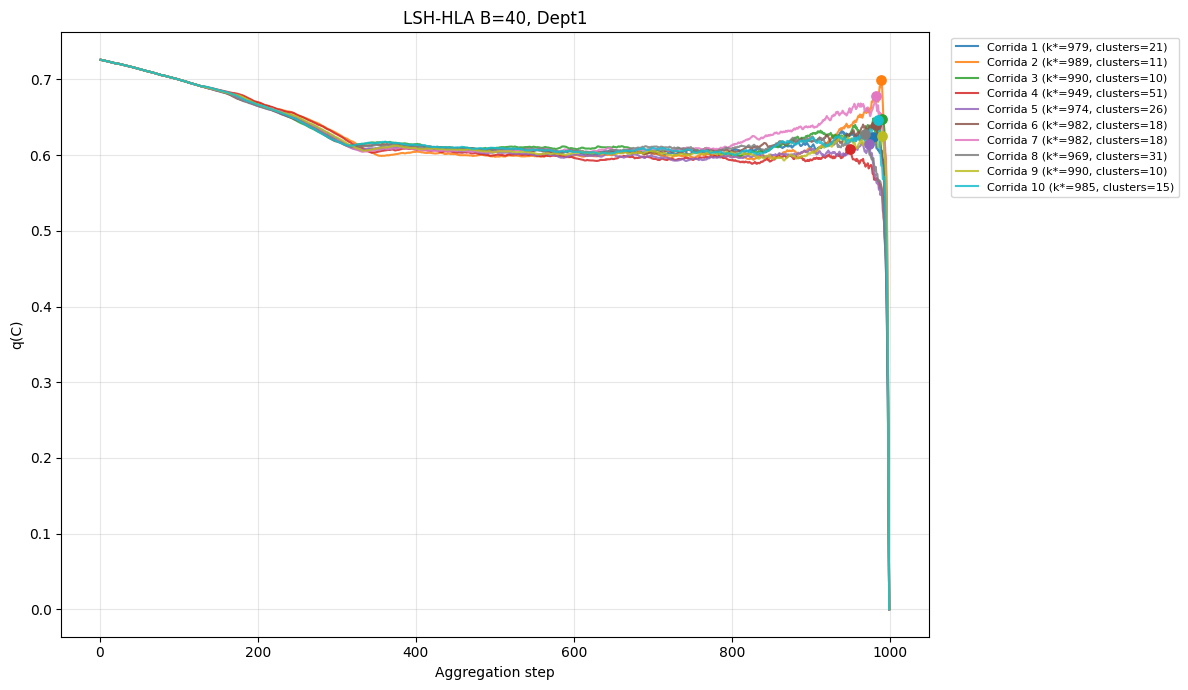

In [22]:
fig, ax = plt.subplots(figsize=(12,7))
colors = plt.get_cmap('tab10')
for i, (row, q_values) in enumerate(zip(run_data_temp, run_quality_temp)):
    cut = row['Aggregation step (k*)']
    ax.plot(np.arange(1,len(q_values)+1), q_values, color=colors(i), linewidth=1.5,
            alpha=.85, label=f"Corrida {i+1} (k*={cut}, clusters={row['# Clusters']})")
    ax.scatter(cut,q_values[cut-1],color=colors(i),marker='o',s=45,zorder=5)
ax.set(xlabel='Aggregation step', ylabel='q(C)',
       title='LSH-HLA B=40, Dept1')
ax.grid(alpha=.3)
ax.legend(fontsize=8, bbox_to_anchor=(1.02,1), loc='upper left')
fig.tight_layout()

plt.show()

In [23]:
4*4

16